Import libraries

In [1]:
import matplotlib.pyplot as plt
import csv
from matplotlib.animation import FuncAnimation

Create a dataset first

Create functions needed?

In [2]:
def load_data(file_path):
    with open(file_path, 'r', newline='') as f:
        reader = csv.reader(f)
        data = list(reader)

    X, y =zip(*data[1:])
    X = list(map(float, X))
    y = list(map(float, y))
    return X, y

def predict(X, w, b):
    return [w * x + b for x in X]

def compute_cost(y_pred, y):
    total = 0
    for i in range(len(y)):
        total += (y_pred[i] - y[i]) ** 2
    cost = total / len(y)
    return cost

def gradient_descent(y_pred, X, y):
    dW = 0
    db = 0
    const = 2 / len(y)
    for i in range(len(y)):
        x = X[i]
        error = y_pred[i] - y[i]
        dW += const * error * x
        db += const * error

    return dW, db



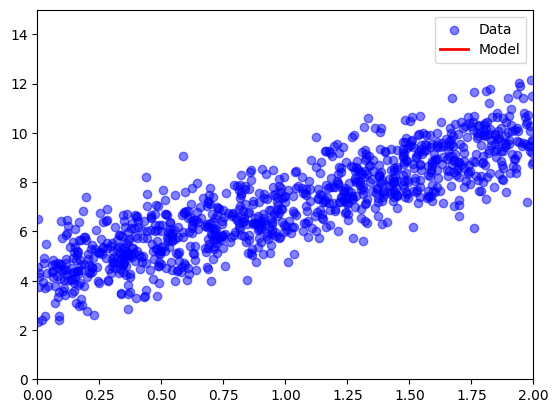

In [3]:
X, y = load_data('train.csv')
W, b = 0, 0
lr = 0.01

#set up the grid
fig, ax = plt.subplots()
ax.scatter(X, y, color='blue', alpha=0.5, label='Data')
line, = ax.plot([], [], color='red', lw=2, label='Model') # Empty line
ax.set_xlim(0, 2)
ax.set_ylim(0, 15)
ax.legend()

title = ax.set_title("")

def init():
    line.set_data([], [])
    return [line]

def update(frame):
    global W, b
    
    prediction = predict(X, W, b)
    cost = compute_cost(prediction, y)
    dW, db = gradient_descent(prediction, X, y)
    W -= lr * dW
    b -= lr * db

    title.set_text(f"Iteration: {frame} | cost: {round(cost, 4)}")
    x_line = [0, 2]
    y_line = [W * x_line[0] + b, W * x_line[1] + b]
    line.set_data(x_line, y_line)
    return [line, title]
    
    


In [4]:
ani = FuncAnimation(fig, update, frames=100, init_func=init, blit=True, interval=50)

from IPython.display import HTML
HTML(ani.to_jshtml())